# Análisis inicial: radiación cósmica galáctica en rutas australes (CARI-7)

**Estudio de escenarios.** Trayectorias geodésicas sintéticas, perfiles y duraciones supuestos, condiciones promedio mensuales de CARI-7, sólo radiación cósmica galáctica (sin eventos solares). No reconstruye vuelos reales ni es una herramienta operacional. Las dosis no se convierten en riesgos individuales ni se extraen conclusiones clínicas.

Todas las cifras de este notebook se leen de los archivos de la ejecución; ninguna está escrita a mano.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import Image, display

ROOT = Path('/Users/mhaacke/Repository/AirRadiation/AirRadiation')
RUN = ROOT / 'runs/syd_scl_austral_v2'
REP = RUN / 'report'
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 30)
pd.set_option('display.float_format', lambda x: f'{x:,.4g}')
manifest = json.loads((RUN / 'manifest.json').read_text())
summary = pd.read_csv(REP / 'flights_summary.csv')
comp = pd.read_csv(REP / 'comparisons.csv')
try:
    annual = pd.read_csv(REP / 'annual_calendars.csv')
except pd.errors.EmptyDataError:  # estudio sin calendarios anuales
    annual = pd.DataFrame()
checks = pd.read_csv(REP / 'validation_checks.csv')
validation = json.loads((REP / 'validation_summary.json').read_text())

## 1. Procedencia de la ejecución

In [2]:
eng = manifest['engine']
print('run_id        :', manifest['run_id'], '| estado:', manifest['status'])
print('motor         :', eng['engine'], eng['executable'], '| banner:', eng['embedded_banner'])
print('sha256 binario:', eng['executable_sha256'], '|', eng['executable_arch'])
print('runner        :', eng['runner'], eng['docker_image'], eng['docker_platform'])
print('MV-DATES.L99  :', eng['data_files']['SOLARMOD/MV-DATES.L99'])
print('paquete CARI  :', (manifest['cari_install_provenance'] or {}).get('package_sha256'))
print('código        :', manifest['git'])
print('config sha256 :', manifest['config_sha256'])
for a in manifest['assumptions']: print('-', a)

run_id        : syd_scl_austral_v2 | estado: ok
motor         : CARI-7 cari-7_linux_intel_exe | banner: June 24, 2020 (4.1.2)
sha256 binario: adc60bf82bff4ab6832cb8eb2ee2d0e11967cbe0b81eac54ccf8ecb23a78019b | x86-64
runner        : docker debian@sha256:7ff6ba31527b9e336162fa061746c366c4b2032f4d2cff2078bea43f78efe3f8 linux/amd64
MV-DATES.L99  : {'sha256': '8ac3b521d47f71038440d77d4220d78ac298108146aa97ebe59bfb4698addb7c', 'last_entry': '08/2026,    642'}
paquete CARI  : a20d9ca8aec142337be52632fbe6f251545d771bdfc0e6bbb69e7a4ddfc94197
código        : {'commit': 'ece5c2518b1a1eb4304cec3736eed832bf0d033e', 'dirty': True, 'source_tree_sha256': '25bb96ac4803bb60fc6d28ec5bf9bf8cce2a0034e9a264676c59fa26360d56b2'}
config sha256 : 420f86778319cfd122ede34800a07a58cd710383b6d3b63353d32a325576da33
- Sólo radiación cósmica galáctica (GCR). Eventos de partículas solares (SPE/GLE) fuera del alcance.
- Condiciones promedio mensuales de CARI-7 (día=00): sin ajustes horarios por decrecimientos Forbush ni

## 2. Fechas y modulación solar

El potencial heliocéntrico es el dato de modulación que CARI-7 usa. No se presupone el sentido del efecto: lo determina el modelo.

In [3]:
pd.DataFrame([{**{'fecha': k}, **{x: v[x] for x in ('label', 'justification')}} for k, v in manifest['config']['dates'].items()])


,fecha,label,justification
0,2020-02,baja modulación solar (feb-2020),Potencial heliocéntrico mensual en SOLARMOD/MV...
1,2024-10,alta modulación solar (oct-2024),Potencial heliocéntrico mensual en MV-DATES.L9...
2,2026-08,último mes disponible (ago-2026),Último potencial heliocéntrico mensual del paq...


In [4]:
summary.groupby('date')['heliocentric_potential_MV'].first()

date
2020-02     254
2024-10    1040
2026-08     642
Name: heliocentric_potential_MV, dtype: int64

## 3. Dosis por tramo: matriz principal (dosis efectiva ICRP 103, µSv)

In [5]:
main = summary[summary.blocks.str.contains('principal')]
main.pivot_table(index=['route', 'direction'], columns=['date', 'profile'], values='total_dose').round(1)

date                   2020-02             2024-10             2026-08            
profile                  FL330 FL370 FL410   FL330 FL370 FL410   FL330 FL370 FL410
route        direction                                                            
SCL-SYD      inbound      53.8    72  91.1    36.2  47.7  59.1    43.2  57.3  71.6
SCL-SYD-FR24 inbound      59.5    80 101.7    39.2  51.8  64.3    47.1  62.7  78.6

Tasa media temporal, tasa máxima y dosis por hora de vuelo (µSv/h). La dosis por hora es la dosis de CARI dividida por el tiempo en el aire; la tasa media es el promedio temporal de las tasas locales; deben coincidir.

In [6]:
cols = ['route', 'direction', 'profile', 'date', 'airborne_h', 'total_dose', 'dose_per_flight_hour',
        'mean_rate', 'cruise_mean_rate', 'max_rate', 'max_rate_lat', 'southernmost_lat']
main[cols].sort_values(['route', 'direction', 'date', 'profile'])

,route,direction,profile,date,airborne_h,total_dose,dose_per_flight_hour,mean_rate,cruise_mean_rate,max_rate,max_rate_lat,southernmost_lat
0,SCL-SYD,inbound,FL330,2020-02,13.05,53.76,4.12,4.12,4.379,5.329,-57.96,-61.83
1,SCL-SYD,inbound,FL370,2020-02,13.05,72.02,5.519,5.519,5.901,7.266,-57.96,-61.83
2,SCL-SYD,inbound,FL410,2020-02,13.05,91.14,6.984,6.984,7.562,9.417,-58.02,-61.83
9,SCL-SYD,inbound,FL330,2024-10,13.05,36.25,2.778,2.778,2.941,3.29,-57.72,-61.83
10,SCL-SYD,inbound,FL370,2024-10,13.05,47.73,3.657,3.657,3.896,4.393,-57.35,-61.83
11,SCL-SYD,inbound,FL410,2024-10,13.05,59.09,4.528,4.528,4.88,5.543,-57.96,-61.83
18,SCL-SYD,inbound,FL330,2026-08,13.05,43.2,3.31,3.31,3.511,4.059,-58.02,-61.83
19,SCL-SYD,inbound,FL370,2026-08,13.05,57.29,4.39,4.39,4.684,5.469,-57.96,-61.83
20,SCL-SYD,inbound,FL410,2026-08,13.05,71.59,5.486,5.486,5.924,6.979,-57.9,-61.83
3,SCL-SYD-FR24,inbound,FL330,2020-02,13.75,59.49,4.327,4.327,4.593,5.332,-53.06,-72.14


## 4. Diferencias entre escenarios

Diferencias absolutas (µSv) y porcentuales, siempre dentro de una misma magnitud. Son variaciones entre escenarios definidos por el usuario, no incertidumbre del modelo.

In [7]:
for k, g in comp.groupby('comparison'):
    print(f'\n=== {k} ===')
    print(g.groupby('value')[['diff_abs', 'diff_pct', 'dose_per_h_diff_pct']].describe().round(2)[[('diff_abs', 'min'), ('diff_abs', 'max'), ('diff_pct', 'min'), ('diff_pct', 'max'), ('dose_per_h_diff_pct', 'min'), ('dose_per_h_diff_pct', 'max')]].to_string())


=== duración ===
             diff_abs     diff_pct     dose_per_h_diff_pct    
                  min max      min max                 min max
value                                                         
igual_tiempo    -4.22   0    -5.32   0               -0.24   0

=== fecha (modulación solar) ===
        diff_abs        diff_pct        dose_per_h_diff_pct       
             min    max      min    max                 min    max
value                                                             
2024-10   -37.43 -17.52   -36.81 -32.58              -36.81 -32.58
2026-08   -23.08 -10.57    -22.7 -19.65               -22.7 -19.65

=== perfil de altura ===
      diff_abs        diff_pct        dose_per_h_diff_pct       
           min    max      min    max                 min    max
value                                                           
FL330   -20.47 -11.48    -25.6 -24.06               -25.6 -24.06
FL410    11.36  21.73     23.8  27.17                23.8  27.17

=== ruta 

### Sensibilidad a la duración (supuesto ilustrativo de asimetría por viento)

In [8]:
comp[comp.varied == 'duration'][['route', 'direction', 'date', 'airborne_min_ref', 'airborne_min', 'dose_ref', 'dose', 'diff_pct', 'dose_per_h_diff_pct']]

,route,direction,date,airborne_min_ref,airborne_min,dose_ref,dose,diff_pct,dose_per_h_diff_pct
45,SCL-SYD,inbound,2020-02,783,783,72.02,72.02,0,0
46,SCL-SYD,inbound,2024-10,783,783,47.73,47.73,0,0
47,SCL-SYD,inbound,2026-08,783,783,57.29,57.29,0,0
48,SCL-SYD-FR24,inbound,2020-02,825,783,79.97,75.75,-5.282,-0.2014
49,SCL-SYD-FR24,inbound,2024-10,825,783,51.76,49.01,-5.317,-0.2377
50,SCL-SYD-FR24,inbound,2026-08,825,783,62.68,59.36,-5.303,-0.2236


## 5. Magnitudes distintas para el mismo vuelo

Dosis efectiva, H*(10) y dosis absorbida **no son intercambiables**. Se muestran lado a lado; el cociente H*(10)/E es solo descriptivo.

In [9]:
pd.read_csv(REP / 'quantities_same_flight.csv')

,route,direction,profile,duration,date,sampling_min


## 6. Validación

In [10]:
print(json.dumps({k: v for k, v in validation.items() if k != 'convergence'}, indent=1))
pd.DataFrame(validation['convergence'])

{
 "all_flight_checks_ok": true,
 "n_flights": 27,
 "max_abs_integral_rel_diff": 4.69352671255141e-05,
 "max_position_offset_km": 0.006896085554658031,
 "max_depth_rel_diff_on_table_nodes": 1.4971987412071286e-06,
 "max_depth_rel_diff_any": 2.1561292088634332e-05
}


""


In [11]:
checks.describe().T[['min', 'max']]

,min,max
n_steps,783,825
expected_steps,783,825
integral_rel_diff,-9.119e-06,4.694e-05
mean_rate_x_hours_rel_diff,-9.119e-06,4.694e-05
max_position_offset_km,0.006691,0.006896
max_depth_rel_diff,9.753e-06,2.156e-05
max_depth_rel_diff_on_table_nodes,4.527e-07,1.497e-06


## 7. Exposición anual con calendarios hipotéticos

**Aproximación:** repite la dosis de un tramo representativo (media de ambos sentidos o, en las rotaciones, la dosis de cada sentido). No simula las condiciones de cada vuelo del año. Un tramo es un vuelo de ida o de vuelta. No se afirma que estos calendarios cumplan límites laborales u operacionales.

,calendar,date,legs_per_month,legs_total,rotations_equivalent,annual_hours,annual_dose_mSv
0,"1 rot/mes, vuelta geodésica",2020-02,2,24,12,313.2,1.728
1,"1 rot/mes, vuelta geodésica",2024-10,2,24,12,313.2,1.145
2,"1 rot/mes, vuelta geodésica",2026-08,2,24,12,313.2,1.374
3,"1 rot/mes, vuelta austral",2020-02,2,24,12,321.6,1.823
4,"1 rot/mes, vuelta austral",2024-10,2,24,12,321.6,1.193
5,"1 rot/mes, vuelta austral",2026-08,2,24,12,321.6,1.439
6,"2 rot/mes, vuelta geodésica",2020-02,4,48,24,626.4,3.455
7,"2 rot/mes, vuelta geodésica",2024-10,4,48,24,626.4,2.29
8,"2 rot/mes, vuelta geodésica",2026-08,4,48,24,626.4,2.749
9,"2 rot/mes, vuelta austral",2020-02,4,48,24,643.2,3.646


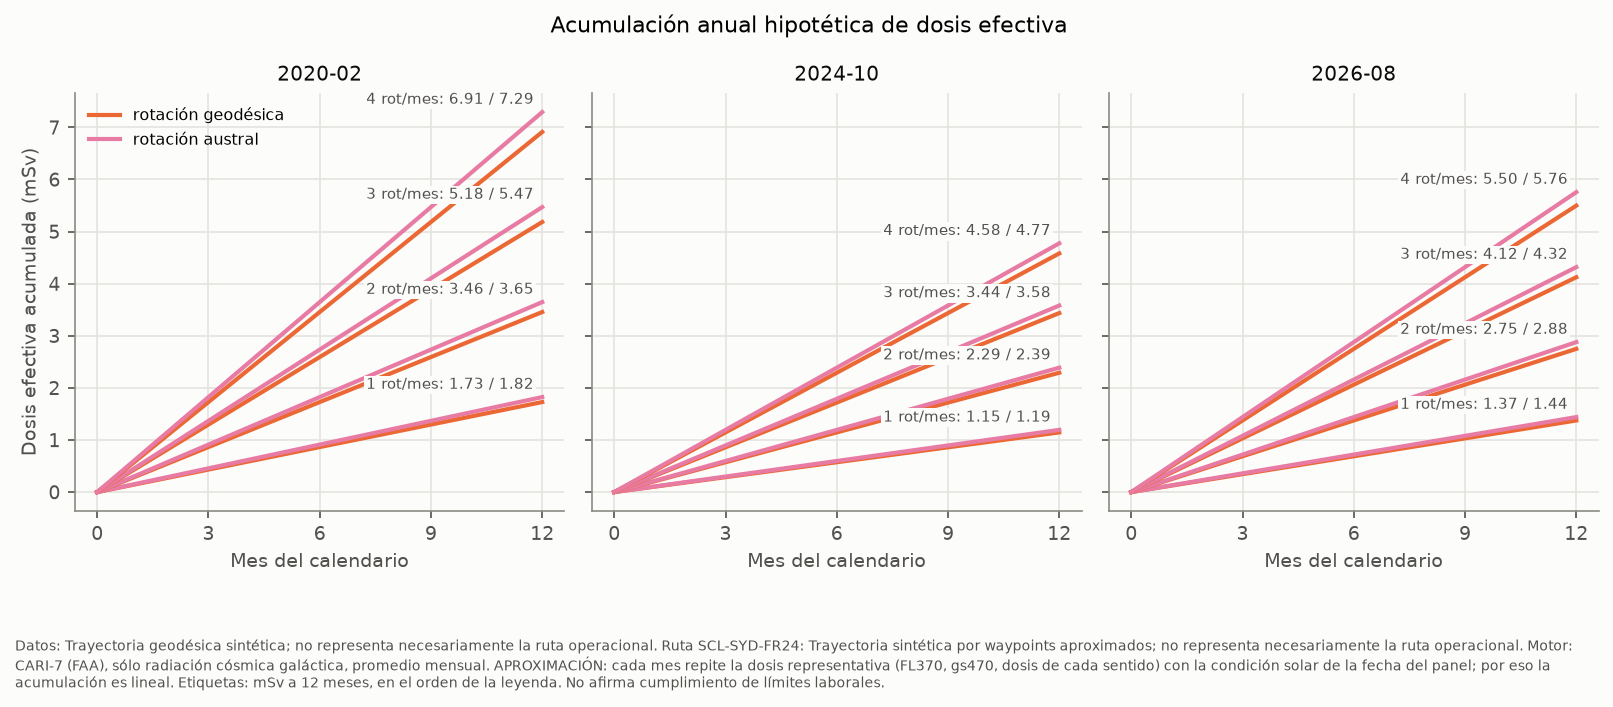

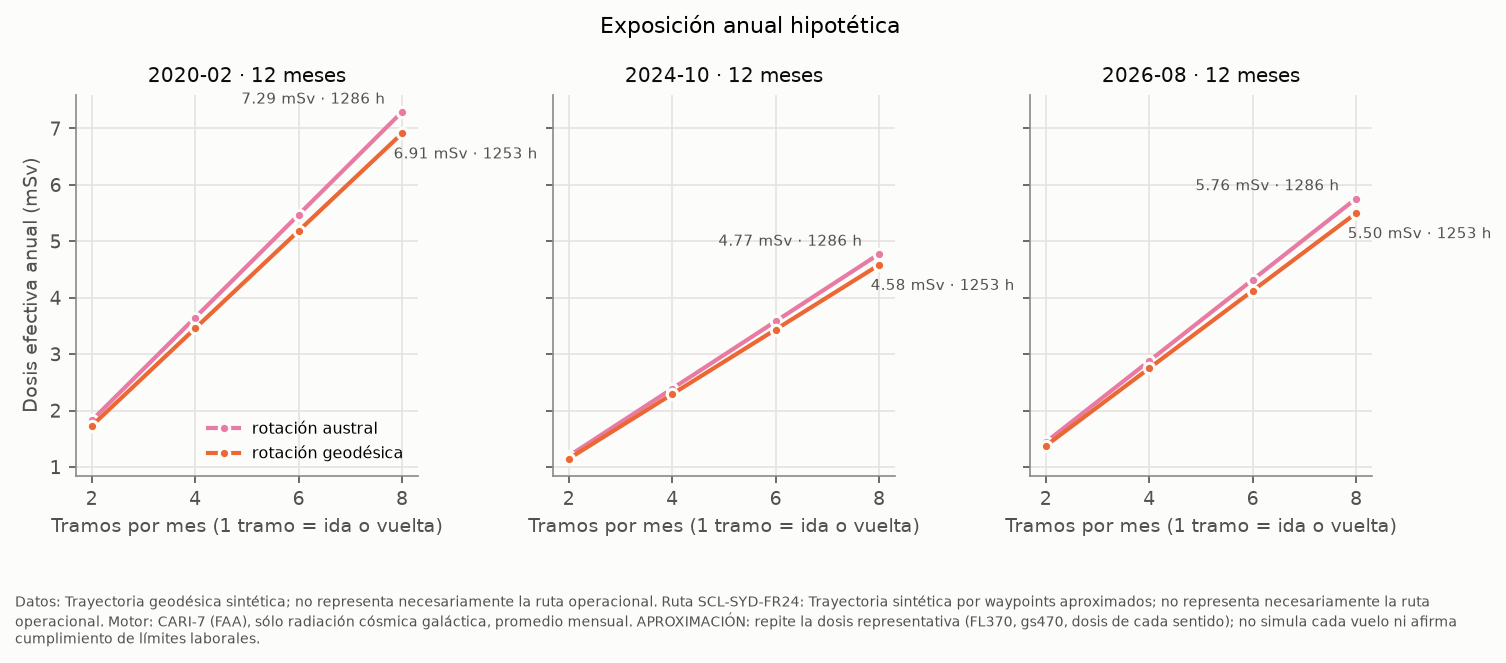

In [12]:
if annual.empty:
    print(manifest['config']['annual']['note'])
else:
    display(annual[['calendar', 'date', 'legs_per_month', 'legs_total', 'rotations_equivalent', 'annual_hours', 'annual_dose_mSv']])
    for f in ['acumulacion_anual', 'exposicion_anual']:
        display(Image(filename=str(REP / 'figures' / f'{f}.png'), width=900))

## 8. Figuras

dosis_acumulada.png


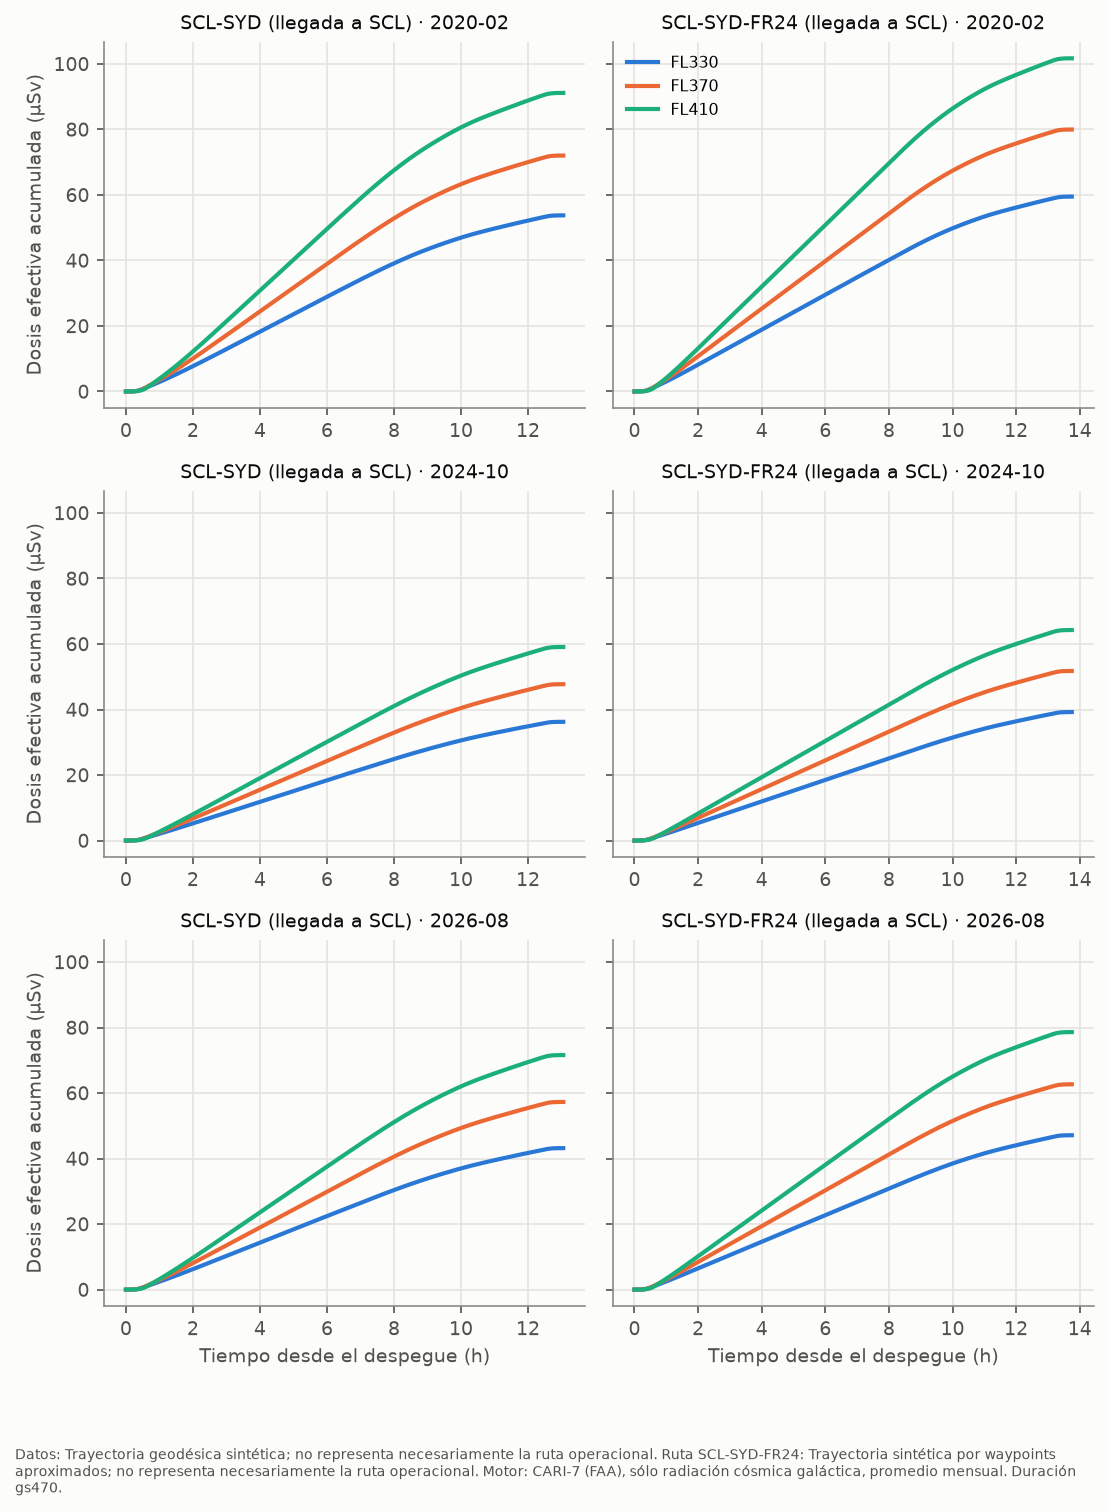

dosis_total_rutas_perfiles.png


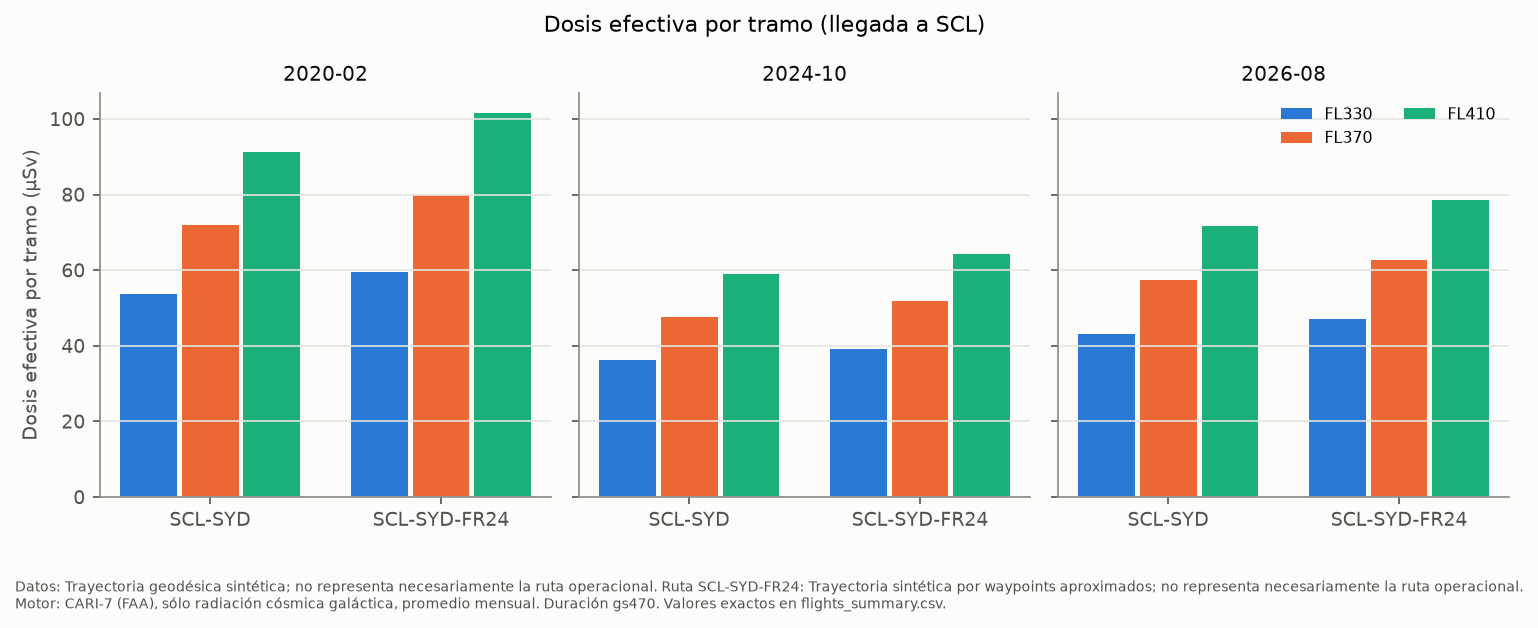

mapa_rutas.png


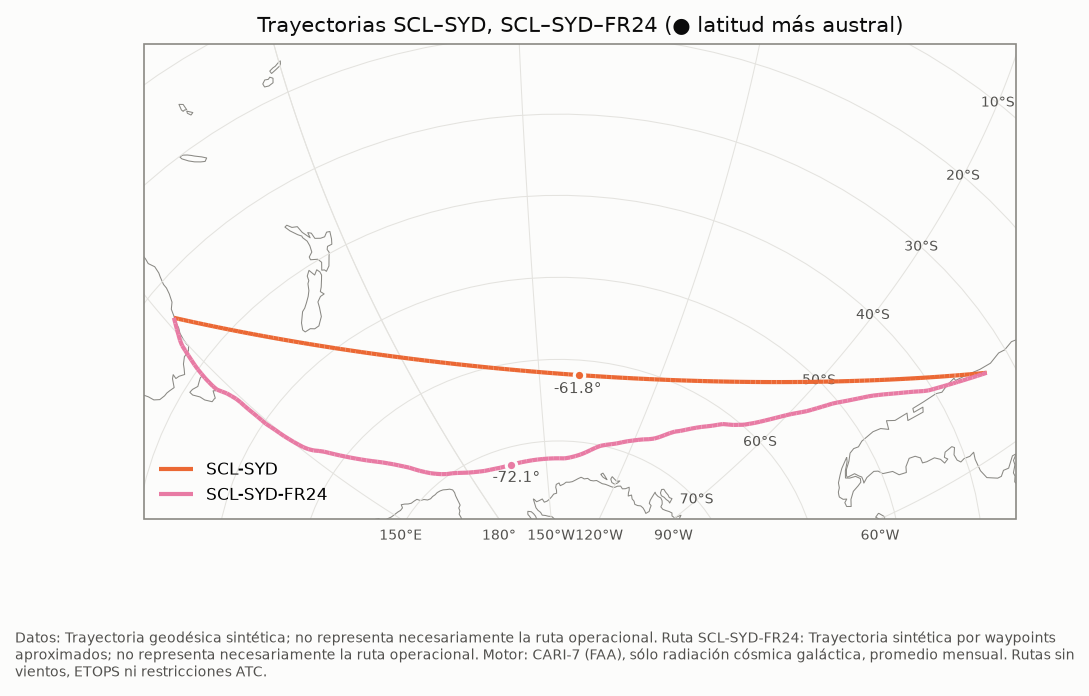

mapa_tasa_2020-02.png


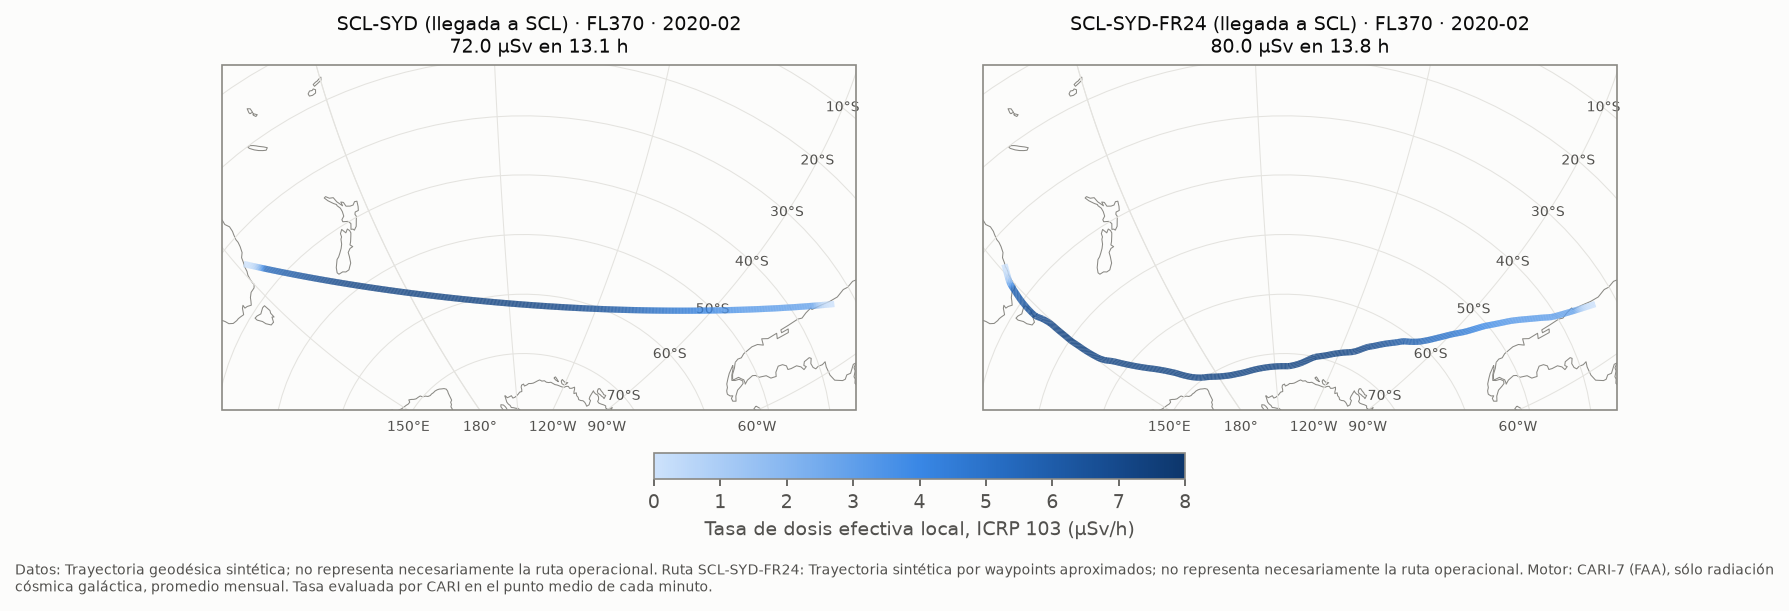

mapa_tasa_2024-10.png


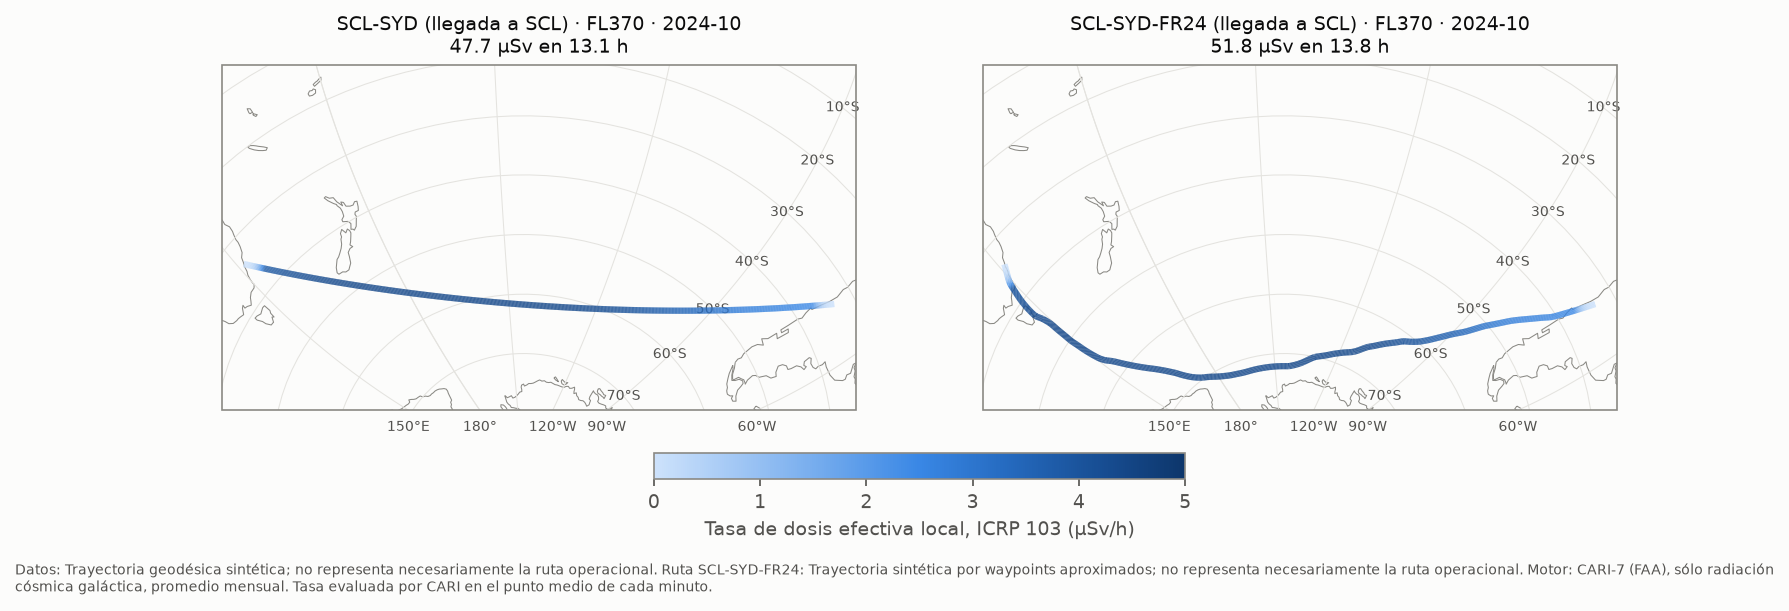

mapa_tasa_2026-08.png


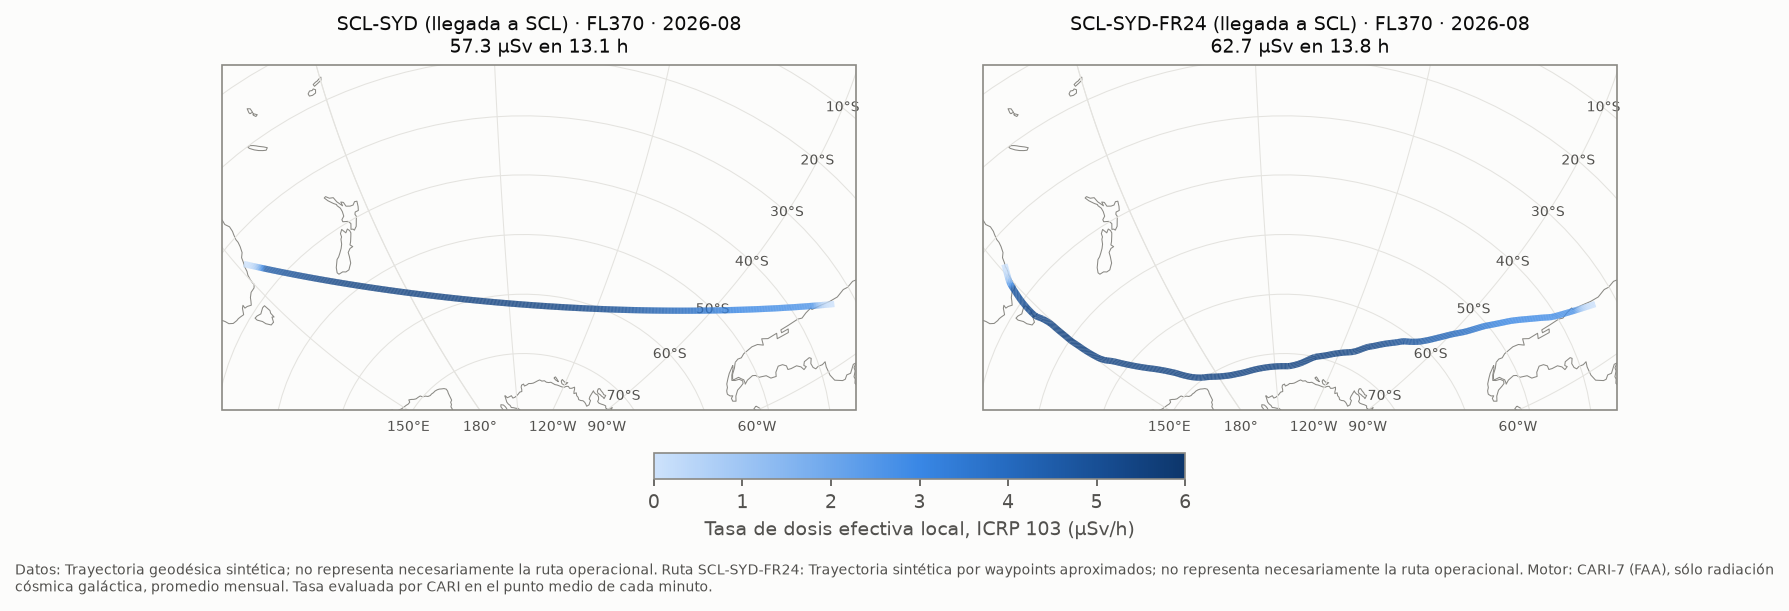

tasa_altitud_SCL-SYD-FR24_in.png


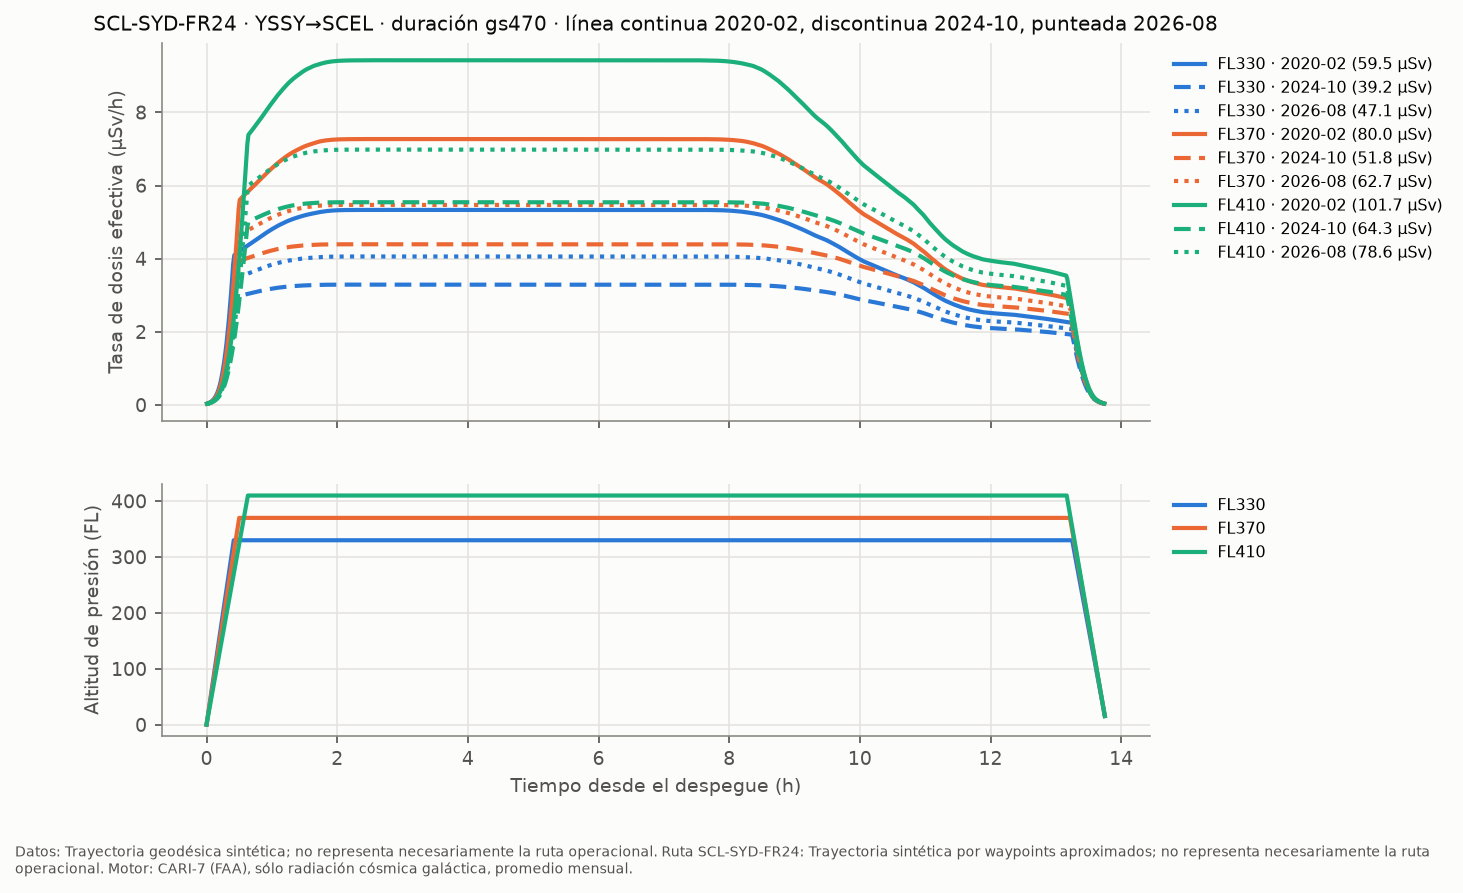

tasa_altitud_SCL-SYD_in.png


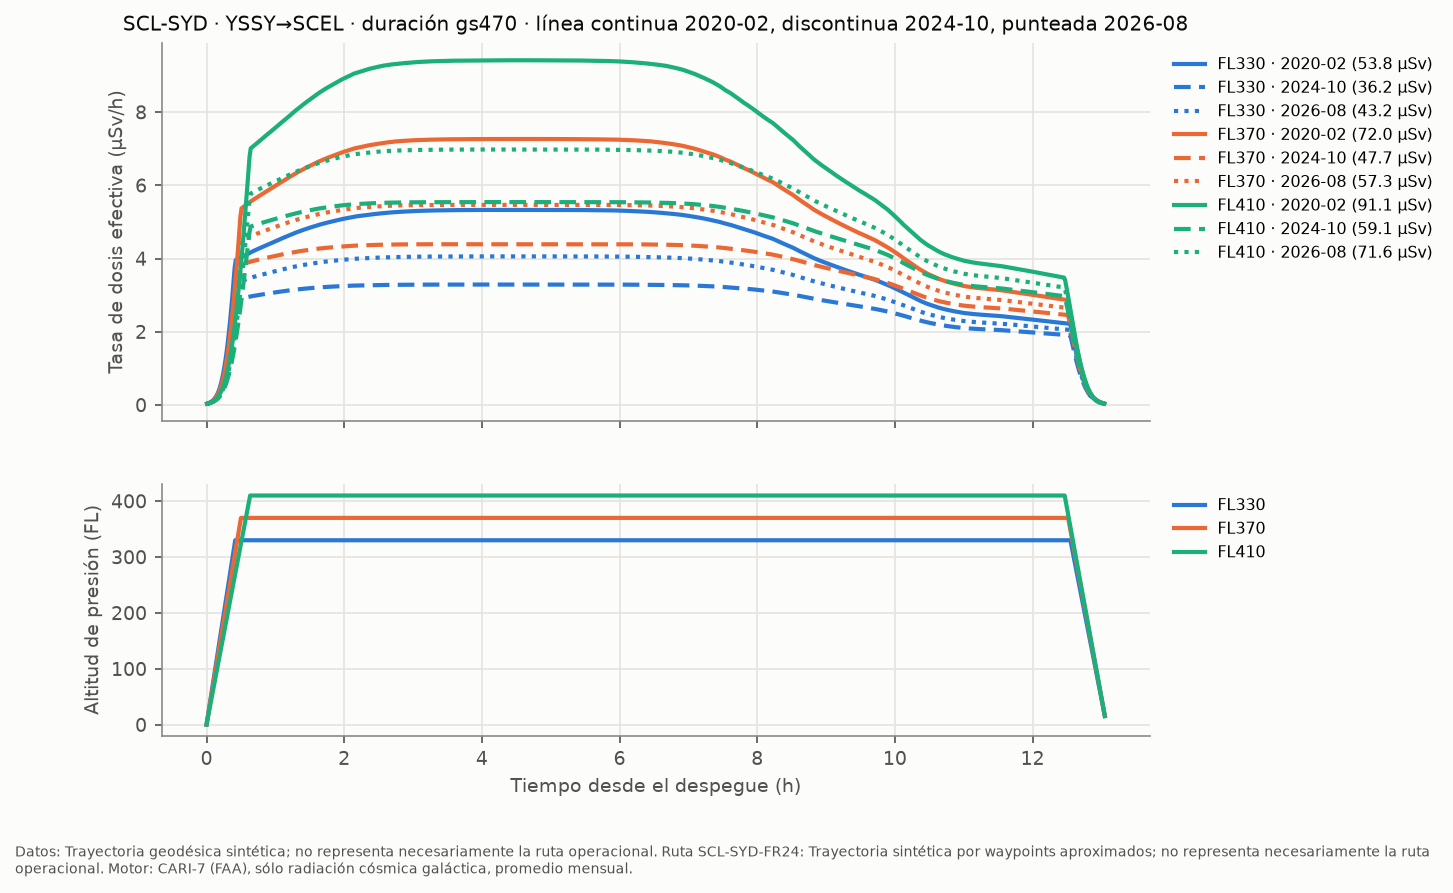

In [13]:
for p in sorted(p for p in (REP / 'figures').glob('*.png') if 'anual' not in p.stem):  # anuales: sección 7
    print(p.name)
    display(Image(filename=str(p), width=900))

## 9. Limitaciones

- Geodésicas sintéticas: las rutas reales dependen de vientos, ETOPS y ATC.
- Promedio mensual: no incluye decrecimientos Forbush ni tormentas geomagnéticas concretas.
- CARI-7 usa la rejilla de rigidez de corte IGRF2010 para fechas posteriores a 2010.
- Sin SPE/GLE. Sin blindaje del fuselaje.
- La incertidumbre global que declara CARI (~30 % a altitudes comerciales, `HELP.TXT`) no es un intervalo de confianza por escenario. Este análisis no calcula intervalos de confianza.